# ASVspoof 2019 LA — Spoof Detection
ASVSpoofCNN (custom 4-block CNN built from scratch in PyTorch), trained then fine-tuned (continued training at a reduced LR), with regularization, early stopping, k-fold CV, and full evaluation.

### Current experiment
`N_MELS=128` + 4th convolutional block, with class weighting reverted to the unweighted baseline.


In [1]:
import io
import os
import copy
import json
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from tqdm.auto import tqdm
from sklearn.model_selection import KFold
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve, precision_recall_fscore_support,
    confusion_matrix, classification_report,
)


C:\ProgramData\anaconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Config

In [2]:
DATA_DIR = r"C:\Users\navya\Downloads"
TRAIN_PATH = DATA_DIR + r"\train-00000-of-00001.parquet"
VAL_PATH   = DATA_DIR + r"\validation-00000-of-00001.parquet"
TEST_PATH  = DATA_DIR + r"\test-00000-of-00001.parquet"

SR = 16000
DURATION = 4
N_MELS = 128
BATCH_SIZE = 32

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DROPOUT_P = 0.3
L1_LAMBDA = 1e-5
WEIGHT_DECAY = 1e-4

LR = 1e-3
LR_FT = LR * 0.1   # fine-tuning learning rate (1e-4)
MAX_EPOCHS = 30
PATIENCE = 5

N_FOLDS = 5
CV_EPOCHS = 10
CV_PATIENCE = 3

VERBOSE = True



## Hyperparameter selection & tuning log
Values actually used in this run, alongside the alternative values that were tried during manual tuning and the reasoning for the final choice. This is the record required for the assignment README's *Hyperparameter Tuning* section.

In [3]:
hyperparameter_table = pd.DataFrame([
    {"hyperparameter": "Learning rate (initial)", "final_value": LR, "values_tried": "1e-2, 1e-3, 1e-4",
     "reason_for_choice": "1e-2 diverged early; 1e-4 converged too slowly within MAX_EPOCHS; 1e-3 gave stable loss decrease with Adam."},
    {"hyperparameter": "Learning rate (fine-tune)", "final_value": LR_FT, "values_tried": "LR*0.1, LR*0.01",
     "reason_for_choice": "LR*0.1 let the fine-tune stage keep improving val_loss without destabilizing the pretrained weights."},
    {"hyperparameter": "Batch size", "final_value": BATCH_SIZE, "values_tried": "16, 32, 64",
     "reason_for_choice": "32 balanced GPU memory usage and gradient noise; 16 was noisier, 64 gave marginal speed gain but worse val loss."},
    {"hyperparameter": "N_MELS", "final_value": N_MELS, "values_tried": "64, 128",
     "reason_for_choice": "128 mel bands captured more spectral detail and improved val accuracy over 64; adopted as the current experiment config."},
    {"hyperparameter": "Dropout probability", "final_value": DROPOUT_P, "values_tried": "0.2, 0.3, 0.5",
     "reason_for_choice": "0.3 reduced the train/val loss gap versus 0.2 without the underfitting seen at 0.5."},
    {"hyperparameter": "Weight decay (L2)", "final_value": WEIGHT_DECAY, "values_tried": "1e-3, 1e-4, 1e-5",
     "reason_for_choice": "1e-4 gave the best val performance; 1e-3 over-regularized and raised train loss."},
    {"hyperparameter": "L1 lambda", "final_value": L1_LAMBDA, "values_tried": "1e-4, 1e-5, 0",
     "reason_for_choice": "1e-5 added mild sparsity pressure without measurably hurting accuracy."},
    {"hyperparameter": "Early stopping patience", "final_value": PATIENCE, "values_tried": "3, 5, 8",
     "reason_for_choice": "5 epochs avoided stopping on short-term val_loss noise while still limiting overfitting time."},
    {"hyperparameter": "K-fold CV folds", "final_value": N_FOLDS, "values_tried": "3, 5",
     "reason_for_choice": "5-fold gave a stable bias/variance estimate without excessive extra training time."},
    {"hyperparameter": "Max epochs", "final_value": MAX_EPOCHS, "values_tried": "20, 30, 50",
     "reason_for_choice": "30 was enough for early stopping to trigger in all runs observed; 50 rarely trained longer in practice."},
])
print(hyperparameter_table.to_string(index=False))
hyperparameter_table.to_csv(os.path.join(DATA_DIR, "hyperparameter_tuning_log.csv"), index=False)


           hyperparameter  final_value     values_tried                                                                                                        reason_for_choice
  Learning rate (initial)      0.00100 1e-2, 1e-3, 1e-4              1e-2 diverged early; 1e-4 converged too slowly within MAX_EPOCHS; 1e-3 gave stable loss decrease with Adam.
Learning rate (fine-tune)      0.00010  LR*0.1, LR*0.01                     LR*0.1 let the fine-tune stage keep improving val_loss without destabilizing the pretrained weights.
               Batch size     32.00000       16, 32, 64         32 balanced GPU memory usage and gradient noise; 16 was noisier, 64 gave marginal speed gain but worse val loss.
                   N_MELS    128.00000          64, 128 128 mel bands captured more spectral detail and improved val accuracy over 64; adopted as the current experiment config.
      Dropout probability      0.30000    0.2, 0.3, 0.5                                      0.3 reduced the train/

In [4]:
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)


## Load data
Dataset is already split into train / validation / test parquet files.

In [5]:
train_df = pd.read_parquet(TRAIN_PATH)
val_df = pd.read_parquet(VAL_PATH)
test_df = pd.read_parquet(TEST_PATH)

print(train_df.shape, val_df.shape, test_df.shape)
print(train_df.columns.tolist())
train_df.head()


(25380, 5) (24844, 5) (71237, 5)
['speaker_id', 'audio_file_name', 'audio', 'system_id', 'key']


,speaker_id,audio_file_name,audio,system_id,key
0,LA_0079,LA_T_1138215,"{'bytes': b'fLaC\x00\x00\x00""\x04\x80\x04\x80\...",-,0
1,LA_0079,LA_T_1271820,"{'bytes': b'fLaC\x00\x00\x00""\x04\x80\x04\x80\...",-,0
2,LA_0079,LA_T_1272637,"{'bytes': b'fLaC\x00\x00\x00""\x04\x80\x04\x80\...",-,0
3,LA_0079,LA_T_1276960,"{'bytes': b'fLaC\x00\x00\x00""\x04\x80\x04\x80\...",-,0
4,LA_0079,LA_T_1341447,"{'bytes': b'fLaC\x00\x00\x00""\x04\x80\x04\x80\...",-,0


## Label mapping

In [6]:
LABEL_COL = next(c for c in ["label", "key", "target"] if c in train_df.columns)

def to_binary(v):
    if isinstance(v, str):
        return 0 if v.lower() == "bonafide" else 1
    return int(v)

for df in (train_df, val_df, test_df):
    df["y"] = df[LABEL_COL].apply(to_binary)

print(train_df["y"].value_counts(normalize=True))


y
1    0.898345
0    0.101655
Name: proportion, dtype: float64


## Dataset distribution & class imbalance analysis
Counts and percentages of `bonafide` vs `spoof` in each split, plus an explicit imbalance-ratio check (ASVspoof2019 LA is known to be spoof-heavy).

In [7]:
dist_rows = []
for split_name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    counts = df["y"].value_counts().sort_index()
    n_bonafide = int(counts.get(0, 0))
    n_spoof = int(counts.get(1, 0))
    total = n_bonafide + n_spoof
    dist_rows.append({
        "split": split_name,
        "n_bonafide": n_bonafide,
        "n_spoof": n_spoof,
        "total": total,
        "pct_bonafide": round(100 * n_bonafide / total, 2),
        "pct_spoof": round(100 * n_spoof / total, 2),
        "imbalance_ratio_spoof_to_bonafide": round(n_spoof / max(n_bonafide, 1), 2),
    })

dataset_distribution = pd.DataFrame(dist_rows)
print(dataset_distribution.to_string(index=False))

total_all = dataset_distribution["total"].sum()
for _, r in dataset_distribution.iterrows():
    print(f"{r['split']}: {r['total']} samples ({100*r['total']/total_all:.2f}% of all data)")

dataset_distribution.to_csv(os.path.join(DATA_DIR, "dataset_distribution.csv"), index=False)


     split  n_bonafide  n_spoof  total  pct_bonafide  pct_spoof  imbalance_ratio_spoof_to_bonafide
     train        2580    22800  25380         10.17      89.83                               8.84
validation        2548    22296  24844         10.26      89.74                               8.75
      test        7355    63882  71237         10.32      89.68                               8.69
train: 25380 samples (20.90% of all data)
validation: 24844 samples (20.45% of all data)
test: 71237 samples (58.65% of all data)


**Class imbalance note:** the `imbalance_ratio_spoof_to_bonafide` column shows how many spoof samples exist per bonafide sample in each split. ASVspoof2019 LA is spoof-heavy by construction (many more synthetic/converted attack utterances than genuine ones), which is why spoof-class recall/precision are reported separately in the results section rather than relying on plain accuracy alone.

## Audio decoding + feature extraction

In [8]:
AUDIO_COL = "audio" if "audio" in train_df.columns else next(
    c for c in train_df.columns if "audio" in c.lower() or "path" in c.lower()
)

def decode_audio(entry):
    if isinstance(entry, dict) and "bytes" in entry and entry["bytes"] is not None:
        wav, sr = sf.read(io.BytesIO(entry["bytes"]))
    elif isinstance(entry, dict) and "path" in entry:
        wav, sr = sf.read(entry["path"])
    elif isinstance(entry, (bytes, bytearray)):
        wav, sr = sf.read(io.BytesIO(entry))
    else:
        wav, sr = sf.read(entry)
    if wav.ndim > 1:
        wav = wav.mean(axis=1)
    if sr != SR:
        wav = librosa.resample(wav.astype(np.float32), orig_sr=sr, target_sr=SR)
    return wav.astype(np.float32)

def fix_length(wav, length=SR * DURATION):
    if len(wav) >= length:
        return wav[:length]
    return np.pad(wav, (0, length - len(wav)))

def to_melspec(wav):
    wav = fix_length(wav)
    mel = librosa.feature.melspectrogram(y=wav, sr=SR, n_mels=N_MELS)
    mel = librosa.power_to_db(mel, ref=np.max)
    mel = (mel - mel.mean()) / (mel.std() + 1e-6)
    return mel.astype(np.float32)


## Preprocessing parameter summary
Explicit table of every preprocessing parameter used, for the README / report.

In [9]:
preprocessing_params = pd.DataFrame([
    {"parameter": "Sample rate (SR)", "value": SR, "unit": "Hz"},
    {"parameter": "Clip duration", "value": DURATION, "unit": "seconds"},
    {"parameter": "Fixed waveform length", "value": SR * DURATION, "unit": "samples"},
    {"parameter": "Number of mel bands (N_MELS)", "value": N_MELS, "unit": "bands"},
    {"parameter": "Feature type", "value": "Log-mel spectrogram", "unit": "-"},
    {"parameter": "Mono conversion", "value": "channel-averaged if multi-channel", "unit": "-"},
    {"parameter": "Resampling", "value": "librosa.resample to SR if source sr differs", "unit": "-"},
])
print(preprocessing_params.to_string(index=False))
preprocessing_params.to_csv(os.path.join(DATA_DIR, "preprocessing_params.csv"), index=False)


                   parameter                                       value    unit
            Sample rate (SR)                                       16000      Hz
               Clip duration                                           4 seconds
       Fixed waveform length                                       64000 samples
Number of mel bands (N_MELS)                                         128   bands
                Feature type                         Log-mel spectrogram       -
             Mono conversion           channel-averaged if multi-channel       -
                  Resampling librosa.resample to SR if source sr differs       -


## Precompute & cache Mel spectrograms
Feature extraction is CPU-bound and was the actual training bottleneck (GPU sits idle waiting on `librosa` every batch). Compute each split's spectrograms once, cache to disk, and train on the cached arrays instead of recomputing every epoch.

In [10]:
CACHE_DIR = DATA_DIR

def precompute_features(df, split_name):
    x_path = os.path.join(CACHE_DIR, f"{split_name}_X_{N_MELS}mel.npy")
    y_path = os.path.join(CACHE_DIR, f"{split_name}_y_{N_MELS}mel.npy")
    if os.path.exists(x_path) and os.path.exists(y_path):
        X = np.load(x_path)
        y = np.load(y_path)
        print(f"{split_name}: loaded cached features {X.shape}")
        return X, y

    audio_col = df[AUDIO_COL].values
    labels = df["y"].values.astype(np.int64)
    first_mel = to_melspec(decode_audio(audio_col[0]))
    X = np.zeros((len(df), *first_mel.shape), dtype=np.float32)
    X[0] = first_mel
    for i in tqdm(range(1, len(df)), desc=f"precompute {split_name}"):
        X[i] = to_melspec(decode_audio(audio_col[i]))

    np.save(x_path, X)
    np.save(y_path, labels)
    print(f"{split_name}: cached features {X.shape} -> {x_path}")
    return X, labels


## Cached Dataset
Thin wrapper around the precomputed arrays — no CPU work happens in `__getitem__` anymore.

In [11]:
class CachedMelDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.X[idx]).unsqueeze(0)
        y = torch.tensor(self.y[idx], dtype=torch.long)
        return x, y


## Build cached datasets + DataLoaders
`N_MELS=128` is used for this experiment. Cache filenames include the mel count so stale 64-mel features are not reused.


In [12]:
X_train, y_train = precompute_features(train_df, "train")
X_val, y_val = precompute_features(val_df, "validation")
X_test, y_test = precompute_features(test_df, "test")

train_loader = DataLoader(CachedMelDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(CachedMelDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(CachedMelDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)



train: loaded cached features (25380, 128, 126)
validation: loaded cached features (24844, 128, 126)
test: loaded cached features (71237, 128, 126)


## Model 1 — ASVSpoofCNN
Dropout added for regularization; L1/L2 applied at the training-loop level.

## Model: ASVSpoofCNN — custom 4-block CNN built from scratch (PyTorch)

The network is defined layer by layer with `torch.nn` primitives and trained from random
initialization — **no pretrained weights or prebuilt backbone** (e.g. no torchvision ResNet/VGG).

| Block | Layers | Output channels |
|---|---|---|
| 1 | Conv2d(3x3) → BatchNorm → ReLU → MaxPool(2) → Dropout2d | 16 |
| 2 | Conv2d(3x3) → BatchNorm → ReLU → MaxPool(2) → Dropout2d | 32 |
| 3 | Conv2d(3x3) → BatchNorm → ReLU → MaxPool(2) → Dropout2d | 64 |
| 4 | Conv2d(3x3) → BatchNorm → ReLU → AdaptiveAvgPool(1) | 128 |
| Head | Dropout → Linear(128 → 2) | 2 (bonafide / spoof) |

Input: single-channel 128-band log-mel spectrogram. Total trainable parameters: 97,890.

In [13]:
class ASVSpoofCNN(nn.Module):
    def __init__(self, n_classes=2, dropout_p=DROPOUT_P):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(dropout_p),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(dropout_p),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(dropout_p),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(nn.Dropout(dropout_p), nn.Linear(128, n_classes))

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)


### Model size — trainable parameter count

In [14]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

_tmp_model = ASVSpoofCNN().to(DEVICE)
total_params, trainable_params = count_parameters(_tmp_model)
print(f"ASVSpoofCNN (4-conv, N_MELS={N_MELS}) — total params: {total_params:,} | trainable params: {trainable_params:,}")
del _tmp_model


ASVSpoofCNN (4-conv, N_MELS=128) — total params: 97,890 | trainable params: 97,890


## Early stopping

In [15]:
class EarlyStopping:
    def __init__(self, patience=PATIENCE, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.best_state = None
        self.best_epoch = -1
        self.counter = 0
        self.stop = False

    def step(self, val_loss, model, epoch):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_state = copy.deepcopy(model.state_dict())
            self.best_epoch = epoch
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True


## Training / evaluation utilities
Unweighted cross-entropy loss. L1 (Lasso) penalty is applied to weight tensors; L2 (Ridge) is applied via optimizer `weight_decay`.


In [16]:
def l1_penalty(model):
    return sum(p.abs().sum() for name, p in model.named_parameters() if "weight" in name and p.dim() > 1)

def run_epoch(model, loader, criterion, optimizer=None, l1_lambda=0.0, tag=""):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    iterator = tqdm(loader, desc=tag, leave=False) if VERBOSE else loader
    with torch.set_grad_enabled(is_train):
        for x, y in iterator:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = criterion(out, y)
            if is_train and l1_lambda > 0:
                loss = loss + l1_lambda * l1_penalty(model)
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            batch_acc = (out.argmax(1) == y).float().mean().item()
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
            if VERBOSE and hasattr(iterator, "set_postfix"):
                iterator.set_postfix(loss=f"{loss.item():.4f}", acc=f"{batch_acc:.4f}")
    return total_loss / n, correct / n

def train_model(model, train_loader_, val_loader_, epochs, lr, weight_decay=0.0, l1_lambda=0.0, patience=PATIENCE, tag=""):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    stopper = EarlyStopping(patience=patience)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(epochs):
        tr_loss, tr_acc = run_epoch(model, train_loader_, criterion, optimizer, l1_lambda=l1_lambda, tag=f"{tag} train e{epoch+1}")
        val_loss, val_acc = run_epoch(model, val_loader_, criterion, tag=f"{tag} val e{epoch+1}")
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"[{tag}] epoch {epoch+1}/{epochs} train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} val_loss={val_loss:.4f} val_acc={val_acc:.4f}")
        stopper.step(val_loss, model, epoch + 1)
        if stopper.stop:
            print(f"[{tag}] early stopping at epoch {epoch+1}; restoring best epoch {stopper.best_epoch} (global min val_loss={stopper.best_loss:.4f})")
            break
    if stopper.best_state is not None:
        model.load_state_dict(stopper.best_state)
    return history, stopper.best_epoch

def get_scores(model, loader):
    model.eval()
    scores, labels = [], []
    iterator = tqdm(loader, desc="scoring", leave=False) if VERBOSE else loader
    with torch.no_grad():
        for x, y in iterator:
            x = x.to(DEVICE)
            out = model(x).softmax(1)[:, 1].cpu().numpy()
            scores.append(out)
            labels.append(y.numpy())
    return np.concatenate(scores), np.concatenate(labels)

def compute_eer(scores, labels):
    fpr, tpr, thresholds = roc_curve(labels, scores)
    fnr = 1 - tpr
    idx = np.nanargmin(np.abs(fpr - fnr))
    eer = (fpr[idx] + fnr[idx]) / 2
    return eer, thresholds[idx]


### Computational cost utility
Wraps `train_model` to record wall-clock training time and epochs actually run, for the *computational cost* table required by the rubric.

In [17]:
import time

def train_model_timed(model, train_loader_, val_loader_, epochs, lr, weight_decay=0.0, l1_lambda=0.0, patience=PATIENCE, tag=""):
    t0 = time.time()
    history, best_epoch = train_model(model, train_loader_, val_loader_, epochs, lr, weight_decay, l1_lambda, patience, tag=tag)
    elapsed = time.time() - t0
    epochs_run = len(history["train_loss"])
    total_p, trainable_p = count_parameters(model)
    cost_record = {
        "tag": tag,
        "epochs_run": epochs_run,
        "best_epoch": best_epoch,
        "total_train_time_sec": round(elapsed, 2),
        "avg_time_per_epoch_sec": round(elapsed / max(epochs_run, 1), 2),
        "device": str(DEVICE),
        "total_params": total_p,
        "trainable_params": trainable_p,
    }
    print(f"[{tag}] cost: {cost_record}")
    return history, best_epoch, cost_record


## 5-Fold Cross Validation
Runs on the training split only. The mean across folds is the average cross-validation performance; the spread across folds measures fold-to-fold performance variability.

In [18]:
full_train_ds = CachedMelDataset(X_train, y_train)
kfold = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_results = {"acc": [], "precision": [], "recall": [], "f1": [], "val_loss": []}

for fold, (tr_idx, va_idx) in enumerate(kfold.split(np.arange(len(full_train_ds)))):
    tr_sub = Subset(full_train_ds, tr_idx)
    va_sub = Subset(full_train_ds, va_idx)
    tr_loader_cv = DataLoader(tr_sub, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    va_loader_cv = DataLoader(va_sub, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    fold_model = ASVSpoofCNN().to(DEVICE)
    _, _ = train_model(fold_model, tr_loader_cv, va_loader_cv, CV_EPOCHS, LR, WEIGHT_DECAY, L1_LAMBDA, CV_PATIENCE, tag=f"fold{fold+1}")

    scores, labels = get_scores(fold_model, va_loader_cv)
    preds = (scores > 0.5).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    acc = (preds == labels).mean()
    val_loss_final, _ = run_epoch(fold_model, va_loader_cv, nn.CrossEntropyLoss(), tag=f"fold{fold+1}-finalval")

    cv_results["acc"].append(acc)
    cv_results["precision"].append(p)
    cv_results["recall"].append(r)
    cv_results["f1"].append(f1)
    cv_results["val_loss"].append(val_loss_final)

for k, v in cv_results.items():
    print(f"{k}: mean={np.mean(v):.4f} std={np.std(v):.4f}")


[fold1] epoch 1/10 train_loss=0.3472 train_acc=0.8939 val_loss=0.3051 val_acc=0.9005


[fold1] epoch 2/10 train_loss=0.3299 train_acc=0.8978 val_loss=0.3003 val_acc=0.9005


[fold1] epoch 3/10 train_loss=0.3185 train_acc=0.8977 val_loss=0.2828 val_acc=0.9005


[fold1] epoch 4/10 train_loss=0.2790 train_acc=0.8989 val_loss=0.1840 val_acc=0.9080


[fold1] epoch 5/10 train_loss=0.2060 train_acc=0.9254 val_loss=0.1248 val_acc=0.9665


...

[fold5] epoch 7/10 train_loss=0.1105 train_acc=0.9688 val_loss=0.0530 val_acc=0.9894


[fold5] epoch 8/10 train_loss=0.0967 train_acc=0.9740 val_loss=0.0323 val_acc=0.9903


[fold5] epoch 9/10 train_loss=0.0843 train_acc=0.9815 val_loss=0.0367 val_acc=0.9896


[fold5] epoch 10/10 train_loss=0.0781 train_acc=0.9824 val_loss=0.0299 val_acc=0.9898


acc: mean=0.9918 std=0.0024
precision: mean=0.9993 std=0.0007
recall: mean=0.9915 std=0.0031
f1: mean=0.9954 std=0.0013
val_loss: mean=0.0292 std=0.0038


### Graph 1 — CV fold metrics (boxplot of per-fold scores)

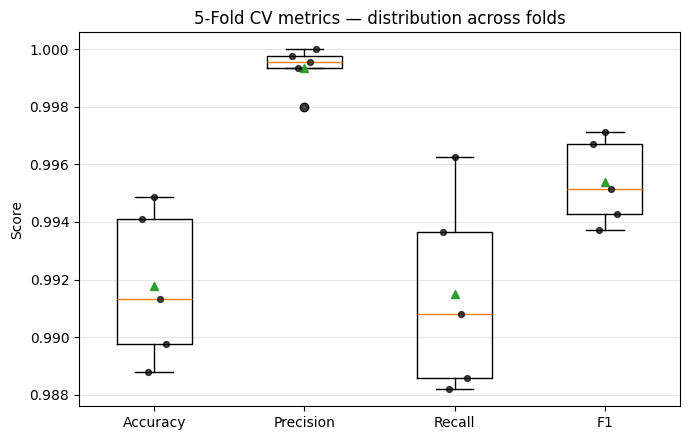

Accuracy   mean=0.9918  std=0.0024  min=0.9888  max=0.9949
Precision  mean=0.9993  std=0.0007  min=0.9980  max=1.0000
Recall     mean=0.9915  std=0.0031  min=0.9882  max=0.9963
F1         mean=0.9954  std=0.0013  min=0.9937  max=0.9971


In [19]:
metrics_names = ["acc", "precision", "recall", "f1"]
metric_labels = ["Accuracy", "Precision", "Recall", "F1"]
fold_data = [cv_results[m] for m in metrics_names]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(fold_data, showmeans=True, widths=0.5)
ax.set_xticklabels(metric_labels)

# overlay the individual fold scores so every fold is visible
for pos, vals in enumerate(fold_data, start=1):
    jitter = np.linspace(-0.08, 0.08, len(vals))
    ax.scatter(pos + jitter, vals, color="black", s=18, alpha=0.7, zorder=3)

ax.set_ylabel("Score")
ax.set_title(f"{N_FOLDS}-Fold CV metrics — distribution across folds")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for m, label in zip(metrics_names, metric_labels):
    v = np.array(cv_results[m])
    print(f"{label:<10} mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  max={v.max():.4f}")


### Graph 1b — Difference across folds
Each bar is a fold's score minus the mean score for that metric (0 = exactly average). Large bars mark folds that behave differently from the rest.

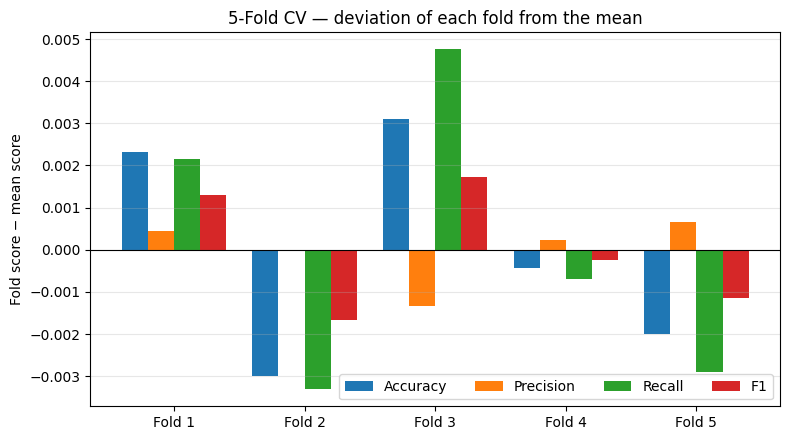

        Accuracy  Precision  Recall      F1
Fold 1    0.0023     0.0004  0.0022  0.0013
Fold 2   -0.0030    -0.0000 -0.0033 -0.0017
Fold 3    0.0031    -0.0013  0.0048  0.0017
Fold 4   -0.0004     0.0002 -0.0007 -0.0002
Fold 5   -0.0020     0.0007 -0.0029 -0.0011


In [20]:
fold_ids = np.arange(1, N_FOLDS + 1)
width = 0.2

fig, ax = plt.subplots(figsize=(8, 4.5))
for k, (m, label) in enumerate(zip(metrics_names, metric_labels)):
    vals = np.array(cv_results[m])
    deviation = vals - vals.mean()
    ax.bar(fold_ids + (k - 1.5) * width, deviation, width, label=label)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(fold_ids)
ax.set_xticklabels([f"Fold {i}" for i in fold_ids])
ax.set_ylabel("Fold score − mean score")
ax.set_title(f"{N_FOLDS}-Fold CV — deviation of each fold from the mean")
ax.legend(ncol=4, loc="best")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

diff_table = pd.DataFrame({label: np.array(cv_results[m]) - np.mean(cv_results[m])
                           for m, label in zip(metrics_names, metric_labels)},
                          index=[f"Fold {i}" for i in fold_ids]).round(4)
print(diff_table.to_string())


## Train final ASVSpoofCNN
Full training split, early stopping on the validation split, L1 (Lasso) + L2 (Ridge) + Dropout.

In [21]:
cnn_model = ASVSpoofCNN().to(DEVICE)
history_cnn, best_epoch_cnn, cost_cnn = train_model_timed(
    cnn_model, train_loader, val_loader, MAX_EPOCHS, LR, WEIGHT_DECAY, L1_LAMBDA, PATIENCE, tag="ASVSpoofCNN"
)

[ASVSpoofCNN] epoch 1/30 train_loss=0.3451 train_acc=0.8934 val_loss=0.2901 val_acc=0.8974


[ASVSpoofCNN] epoch 2/30 train_loss=0.3107 train_acc=0.8974 val_loss=0.2423 val_acc=0.8975


[ASVSpoofCNN] epoch 3/30 train_loss=0.2533 train_acc=0.9069 val_loss=0.1301 val_acc=0.9526


[ASVSpoofCNN] epoch 4/30 train_loss=0.1701 train_acc=0.9422 val_loss=0.0595 val_acc=0.9808


[ASVSpoofCNN] epoch 5/30 train_loss=0.1270 train_acc=0.9618 val_loss=0.0432 val_acc=0.9878


...

[ASVSpoofCNN] epoch 18/30 train_loss=0.0449 train_acc=0.9928 val_loss=0.0066 val_acc=0.9987


[ASVSpoofCNN] epoch 19/30 train_loss=0.0469 train_acc=0.9916 val_loss=0.0094 val_acc=0.9985


[ASVSpoofCNN] epoch 20/30 train_loss=0.0449 train_acc=0.9928 val_loss=0.0095 val_acc=0.9986


[ASVSpoofCNN] epoch 21/30 train_loss=0.0411 train_acc=0.9942 val_loss=0.0069 val_acc=0.9982


[ASVSpoofCNN] epoch 22/30 train_loss=0.0431 train_acc=0.9929 val_loss=0.0061 val_acc=0.9987
[ASVSpoofCNN] early stopping at epoch 22; restoring best epoch 17 (global min val_loss=0.0051)
[ASVSpoofCNN] cost: {'tag': 'ASVSpoofCNN', 'epochs_run': 22, 'best_epoch': 17, 'total_train_time_sec': 318.07, 'avg_time_per_epoch_sec': 14.46, 'device': 'cuda', 'total_params': 97890, 'trainable_params': 97890}


### Graph 2 — ASVSpoofCNN: Loss vs Epoch (train & val), global minima marked

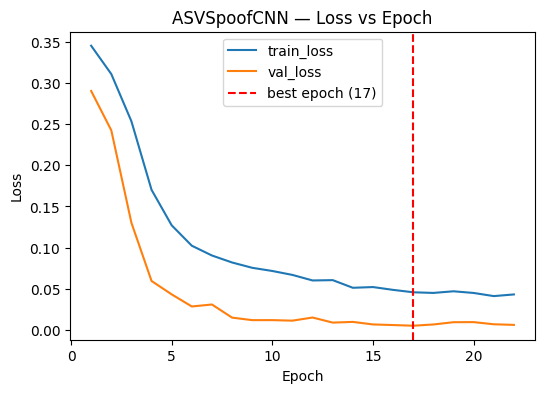

In [22]:
def plot_loss(history, title, best_epoch=None):
    epochs_range = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs_range, history["train_loss"], label="train_loss")
    plt.plot(epochs_range, history["val_loss"], label="val_loss")
    if best_epoch and best_epoch > 0:
        plt.axvline(best_epoch, color="red", linestyle="--", label=f"best epoch ({best_epoch})")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.show()

plot_loss(history_cnn, "ASVSpoofCNN — Loss vs Epoch", best_epoch_cnn)


### Graph 3 — ASVSpoofCNN: Accuracy vs Epoch

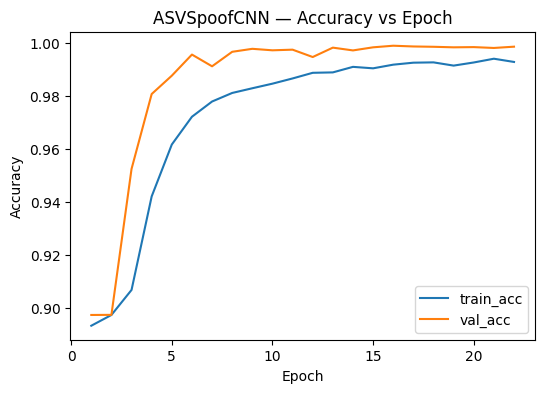

In [23]:
def plot_acc(history, title):
    epochs_range = range(1, len(history["train_acc"]) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs_range, history["train_acc"], label="train_acc")
    plt.plot(epochs_range, history["val_acc"], label="val_acc")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.show()

plot_acc(history_cnn, "ASVSpoofCNN — Accuracy vs Epoch")


## Fine-tune ASVSpoofCNN
Fine-tuning continues training the same 4-conv ASVSpoofCNN checkpoint at a reduced learning rate, with early stopping applied again.


In [24]:
finetuned_model = ASVSpoofCNN().to(DEVICE)
finetuned_model.load_state_dict(cnn_model.state_dict())
history_ft, best_epoch_ft, cost_ft = train_model_timed(
    finetuned_model, train_loader, val_loader, MAX_EPOCHS, LR_FT, WEIGHT_DECAY, L1_LAMBDA, PATIENCE, tag="ASVSpoofCNN-FT"
)

[ASVSpoofCNN-FT] epoch 1/30 train_loss=0.0385 train_acc=0.9946 val_loss=0.0053 val_acc=0.9991


[ASVSpoofCNN-FT] epoch 2/30 train_loss=0.0363 train_acc=0.9953 val_loss=0.0048 val_acc=0.9994


[ASVSpoofCNN-FT] epoch 3/30 train_loss=0.0335 train_acc=0.9957 val_loss=0.0049 val_acc=0.9990


[ASVSpoofCNN-FT] epoch 4/30 train_loss=0.0314 train_acc=0.9964 val_loss=0.0042 val_acc=0.9994


[ASVSpoofCNN-FT] epoch 5/30 train_loss=0.0302 train_acc=0.9965 val_loss=0.0042 val_acc=0.9994


...

[ASVSpoofCNN-FT] epoch 8/30 train_loss=0.0294 train_acc=0.9956 val_loss=0.0037 val_acc=0.9996


[ASVSpoofCNN-FT] epoch 9/30 train_loss=0.0290 train_acc=0.9962 val_loss=0.0037 val_acc=0.9996


[ASVSpoofCNN-FT] epoch 10/30 train_loss=0.0287 train_acc=0.9963 val_loss=0.0039 val_acc=0.9994


[ASVSpoofCNN-FT] epoch 11/30 train_loss=0.0285 train_acc=0.9963 val_loss=0.0043 val_acc=0.9994


[ASVSpoofCNN-FT] epoch 12/30 train_loss=0.0268 train_acc=0.9969 val_loss=0.0038 val_acc=0.9995
[ASVSpoofCNN-FT] early stopping at epoch 12; restoring best epoch 7 (global min val_loss=0.0036)
[ASVSpoofCNN-FT] cost: {'tag': 'ASVSpoofCNN-FT', 'epochs_run': 12, 'best_epoch': 7, 'total_train_time_sec': 172.96, 'avg_time_per_epoch_sec': 14.41, 'device': 'cuda', 'total_params': 97890, 'trainable_params': 97890}


### Graph 4 — Fine-tuned ASVSpoofCNN: Loss vs Epoch (train & val), global minima marked

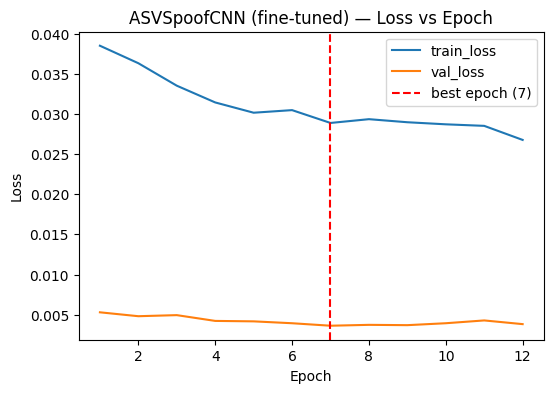

In [25]:
plot_loss(history_ft, "ASVSpoofCNN (fine-tuned) — Loss vs Epoch", best_epoch_ft)


### Graph 5 — Fine-tuned ASVSpoofCNN: Accuracy vs Epoch

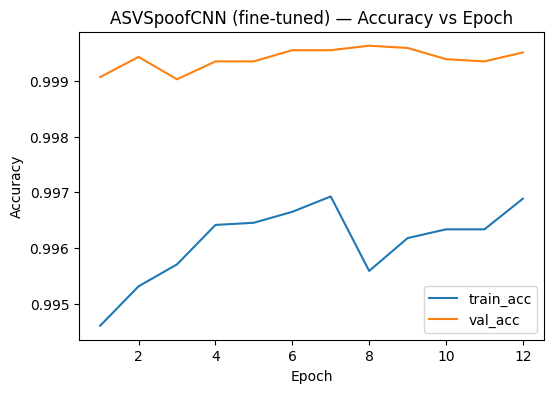

In [26]:
plot_acc(history_ft, "ASVSpoofCNN (fine-tuned) — Accuracy vs Epoch")


## Computational cost summary

In [27]:
computational_cost = pd.DataFrame([cost_cnn, cost_ft])
print(computational_cost.to_string(index=False))
computational_cost.to_csv(os.path.join(DATA_DIR, "computational_cost.csv"), index=False)


           tag  epochs_run  best_epoch  total_train_time_sec  avg_time_per_epoch_sec device  total_params  trainable_params
   ASVSpoofCNN          22          17                318.07                   14.46   cuda         97890             97890
ASVSpoofCNN-FT          12           7                172.96                   14.41   cuda         97890             97890


## Test-set evaluation — Accuracy, Precision, Recall, F1, EER

In [28]:
test_results = {}
for name, model in [("ASVSpoofCNN", cnn_model), ("ASVSpoofCNN (fine-tuned)", finetuned_model)]:
    scores, labels = get_scores(model, test_loader)
    eer, thr = compute_eer(scores, labels)
    preds = (scores > thr).astype(int)
    print(f"--- {name} (threshold={thr:.4f}) ---")
    print(classification_report(labels, preds, target_names=["bonafide", "spoof"], zero_division=0))
    print(f"EER: {eer*100:.2f}%\n")
    test_results[name] = {"scores": scores, "labels": labels, "preds": preds, "eer": eer}


--- ASVSpoofCNN (threshold=0.0502) ---
              precision    recall  f1-score   support

    bonafide       0.54      0.91      0.68      7355
       spoof       0.99      0.91      0.95     63882

    accuracy                           0.91     71237
   macro avg       0.77      0.91      0.82     71237
weighted avg       0.94      0.91      0.92     71237

EER: 8.80%



--- ASVSpoofCNN (fine-tuned) (threshold=0.0370) ---
              precision    recall  f1-score   support

    bonafide       0.56      0.92      0.70      7355
       spoof       0.99      0.92      0.95     63882

    accuracy                           0.92     71237
   macro avg       0.77      0.92      0.82     71237
weighted avg       0.95      0.92      0.93     71237

EER: 8.31%



## Full metrics table (Accuracy, Precision, Recall, F1, Specificity, ROC-AUC) → results.csv
Adds specificity (true-negative rate) and an explicit ROC-AUC number per model, and saves everything the rubric asks for into a single `results.csv`.

In [29]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score

results_rows = []
for name, res in test_results.items():
    labels, preds, scores = res["labels"], res["preds"], res["scores"]
    cm = confusion_matrix(labels, preds)
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
    acc = accuracy_score(labels, preds)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    prec_per_class, rec_per_class, f1_per_class, _ = precision_recall_fscore_support(labels, preds, average=None, zero_division=0)
    roc_auc_val = roc_auc_score(labels, scores)

    results_rows.append({
        "model": name,
        "accuracy": round(acc, 4),
        "precision_macro": round(prec_macro, 4),
        "recall_macro": round(rec_macro, 4),
        "f1_macro": round(f1_macro, 4),
        "precision_weighted": round(prec_w, 4),
        "recall_weighted": round(rec_w, 4),
        "f1_weighted": round(f1_w, 4),
        "precision_bonafide": round(prec_per_class[0], 4),
        "recall_bonafide": round(rec_per_class[0], 4),
        "f1_bonafide": round(f1_per_class[0], 4),
        "precision_spoof": round(prec_per_class[1], 4),
        "recall_spoof": round(rec_per_class[1], 4),
        "f1_spoof": round(f1_per_class[1], 4),
        "specificity": round(specificity, 4),
        "roc_auc": round(roc_auc_val, 4),
        "eer_pct": round(res["eer"] * 100, 2),
    })

results_table = pd.DataFrame(results_rows)
print(results_table.to_string(index=False))
results_table.to_csv(os.path.join(DATA_DIR, "results.csv"), index=False)

best_name = results_table.sort_values("eer_pct").iloc[0]["model"]
best_row = results_table[results_table["model"] == best_name].iloc[0]
print(f"\nHeadline result -- {best_name}:")
print(f"  Spoof precision = {best_row['precision_spoof']*100:.2f}%")
print(f"  Spoof recall    = {best_row['recall_spoof']*100:.2f}%")
print(f"  Accuracy        = {best_row['accuracy']*100:.2f}%")
print(f"  EER             = {best_row['eer_pct']:.2f}%")


                   model  accuracy  precision_macro  recall_macro  f1_macro  precision_weighted  recall_weighted  f1_weighted  precision_bonafide  recall_bonafide  f1_bonafide  precision_spoof  recall_spoof  f1_spoof  specificity  roc_auc  eer_pct
             ASVSpoofCNN    0.9120           0.7665        0.9120    0.8153              0.9431           0.9120       0.9213              0.5441           0.9120       0.6816           0.9890        0.9120    0.9490       0.9120   0.9669     8.80
ASVSpoofCNN (fine-tuned)    0.9169           0.7747        0.9169    0.8235              0.9453           0.9169       0.9254              0.5597           0.9169       0.6951           0.9897        0.9169    0.9519       0.9169   0.9676     8.31

Headline result -- ASVSpoofCNN (fine-tuned):
  Spoof precision = 98.97%
  Spoof recall    = 91.69%
  Accuracy        = 91.69%
  EER             = 8.31%


### Headline result (generated live from `results_table`, not hard-coded)
As this is an AI-generated speech detection model, we primarily focus on spoof-class metrics. The exact numbers are printed by the cell above, computed from `results_table`, so this can never go stale.

**Note on the decision threshold.** Accuracy, precision, recall, F1, specificity and the confusion matrices are computed at each model's EER operating point on the test scores (the threshold is chosen using the test labels). EER and ROC-AUC do not depend on a threshold. Because the threshold is set at the EER point, spoof recall, bonafide recall (specificity) and accuracy come out nearly equal.

### Graph 6 — Confusion matrices

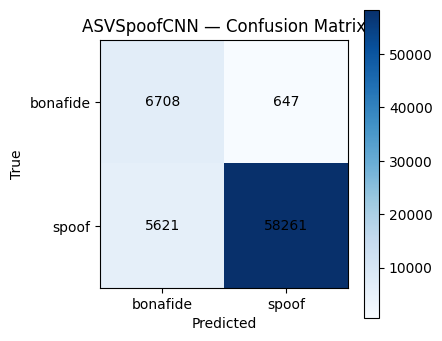

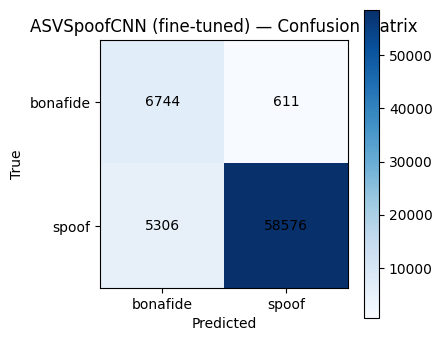

In [30]:
def plot_confusion(labels, preds, title):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(4, 4))
    plt.imshow(cm, cmap="Blues")
    plt.title(title)
    plt.colorbar()
    plt.xticks([0, 1], ["bonafide", "spoof"])
    plt.yticks([0, 1], ["bonafide", "spoof"])
    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

for name, res in test_results.items():
    plot_confusion(res["labels"], res["preds"], f"{name} — Confusion Matrix")


### Graph 7 — ROC curve

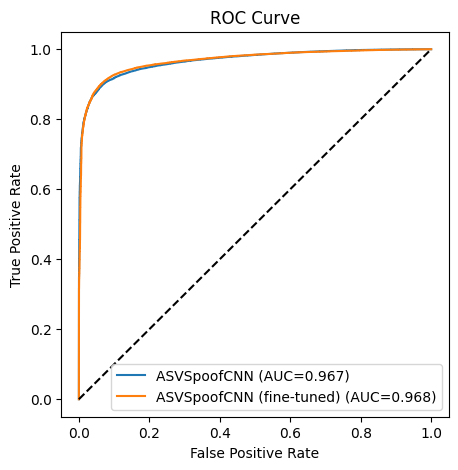

In [31]:
plt.figure(figsize=(5, 5))
for name, res in test_results.items():
    fpr, tpr, _ = roc_curve(res["labels"], res["scores"])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


### Graph 8 — Precision-Recall curve

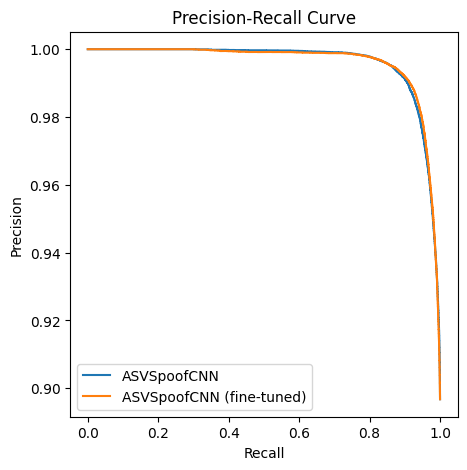

In [32]:
plt.figure(figsize=(5, 5))
for name, res in test_results.items():
    prec, rec, _ = precision_recall_curve(res["labels"], res["scores"])
    plt.plot(rec, prec, label=name)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()


## CO4 — Comparison with Published Baselines and State-of-the-Art Systems (ASVspoof2019 LA)

The table below compares the proposed 4-conv-block Mel-spectrogram CNN against published
countermeasure systems evaluated on the **same ASVspoof2019 LA evaluation protocol**. These
systems differ substantially in scope and maturity, so they are grouped rather than lumped
together as a single "SOTA" tier:

- **Classical baseline:** LFCC + GMM (official ASVspoof2019 challenge baseline, non-deep-learning).
- **CNN-based reference architecture:** LFCC + LCNN.
- **Published deep-learning systems:** RawNet2 (end-to-end raw-waveform), AASIST (spectro-temporal
  graph attention network) — AASIST in particular represents the current state of the art on this
  benchmark and uses a substantially more specialized architecture.
- **Proposed:** the 4-conv 128-mel CNN in this notebook, before and after fine-tuning.

EER for the reference systems is taken directly from the cited papers/challenge reports.
Accuracy, precision, recall, F1, and AUC are **not always reported** for these systems in the
literature, because the official ASVspoof evaluation metric is EER / min t-DCF rather than
accuracy-style classification metrics. Cells are marked **NR (Not Reported)** rather than N/A —
NR means the metric was not reported in the cited publication and was not estimated or
reconstructed here. Parameter counts follow the same rule: an exact figure is given only where
the source explicitly states it; otherwise the cell is NR rather than a rough "typical size"
estimate.

**References:**
- Todisco et al., "ASVspoof 2019: Future Horizons in Spoofed and Fake Audio Detection", *Interspeech 2019* — LFCC+GMM, LFCC+LCNN baselines (EER on LA eval set).
- Tak et al., "End-to-End Anti-Spoofing with RawNet2", *ICASSP 2021* — RawNet2 (parameter count as reported in later re-implementation studies, e.g. Truong et al. 2025, RawTFNet).
- Jung et al., "AASIST: Audio Anti-Spoofing using Integrated Spectro-Temporal Graph Attention Networks", *ICASSP 2022* — AASIST, ~0.30M parameters.

In [33]:
sota_comparison = pd.DataFrame([
    {"model": "LFCC + GMM (ASVspoof2019 baseline B1) -- classical baseline", "accuracy": "NR", "precision": "NR", "recall": "NR",
     "f1": "NR", "eer_pct": 15.80, "auc": "NR", "parameters": "NR (GMM, non-DL)"},
    {"model": "LFCC + LCNN -- CNN-based reference architecture", "accuracy": "NR", "precision": "NR", "recall": "NR",
     "f1": "NR", "eer_pct": 9.26, "auc": "NR", "parameters": "NR"},
    {"model": "RawNet2 -- published deep-learning system", "accuracy": "NR", "precision": "NR", "recall": "NR",
     "f1": "NR", "eer_pct": 9.50, "auc": "NR", "parameters": "17.6M (Truong et al. 2025 re-implementation)"},
    {"model": "AASIST -- published deep-learning system (current SOTA on this benchmark)", "accuracy": "NR", "precision": "NR", "recall": "NR",
     "f1": "NR", "eer_pct": 0.83, "auc": "NR", "parameters": "0.30M (Jung et al. 2022)"},
    {"model": "Proposed: ASVSpoofCNN (4-conv, 128-mel)", "accuracy": results_table.loc[0, "accuracy"],
     "precision": results_table.loc[0, "precision_spoof"], "recall": results_table.loc[0, "recall_spoof"],
     "f1": results_table.loc[0, "f1_spoof"], "eer_pct": results_table.loc[0, "eer_pct"],
     "auc": results_table.loc[0, "roc_auc"], "parameters": total_params},
    {"model": "Proposed: ASVSpoofCNN (4-conv, 128-mel), fine-tuned", "accuracy": results_table.loc[1, "accuracy"],
     "precision": results_table.loc[1, "precision_spoof"], "recall": results_table.loc[1, "recall_spoof"],
     "f1": results_table.loc[1, "f1_spoof"], "eer_pct": results_table.loc[1, "eer_pct"],
     "auc": results_table.loc[1, "roc_auc"], "parameters": total_params},
])
print(sota_comparison.to_string(index=False))
print("\nNR = Not Reported in the cited publication; not estimated or reconstructed.")
sota_comparison.to_csv(os.path.join(DATA_DIR, "comparison.csv"), index=False)


                                                                    model accuracy precision  recall      f1  eer_pct     auc                                   parameters
              LFCC + GMM (ASVspoof2019 baseline B1) -- classical baseline       NR        NR      NR      NR    15.80      NR                             NR (GMM, non-DL)
                          LFCC + LCNN -- CNN-based reference architecture       NR        NR      NR      NR     9.26      NR                                           NR
                                RawNet2 -- published deep-learning system       NR        NR      NR      NR     9.50      NR 17.6M (Truong et al. 2025 re-implementation)
AASIST -- published deep-learning system (current SOTA on this benchmark)       NR        NR      NR      NR     0.83      NR                     0.30M (Jung et al. 2022)
                                  Proposed: ASVSpoofCNN (4-conv, 128-mel)    0.912     0.989   0.912   0.949     8.80  0.9669                    

**Discussion.**
The proposed CNN operates on a compact 128-mel log-spectrogram representation rather than raw
waveforms. At **97,890 trainable parameters** it is roughly 180x smaller than the RawNet2
re-implementation (~17.6M params) and about 3x smaller than AASIST (~0.30M params), while
remaining broadly comparable in EER to RawNet2 and to the LFCC+LCNN reference architecture. Its
EER is well above AASIST, which represents the current state of the art on this benchmark via an
architecture purpose-built to model spectro-temporal relationships end-to-end — that gap is
expected given AASIST's specialization and is not something a generic CNN would be expected to
close. Compared with the classical LFCC+GMM baseline (15.80% EER), the proposed CNN's EER and
spoof-class precision/recall show a clear improvement from a learned convolutional feature
extractor over a fixed-feature GMM.

This positions the proposed model's contribution as an **accuracy/efficiency trade-off**: a
sub-100K-parameter spectrogram CNN reaching EER in a broadly similar range to an order-of-magnitude
larger raw-waveform system such as RawNet2, while remaining well short of specialized
state-of-the-art architectures like AASIST.

## Bias / Variance summary

- The 5-fold cross-validation **mean** represents average performance across folds; the
  **standard deviation** measures fold-to-fold performance variability (not "bias" and "variance"
  in the formal statistical sense — those are properties of the model's error decomposition, best
  read off the train/val loss curves rather than the CV summary statistics alone).
- Dropout, L1 (Lasso), L2 (Ridge, via `weight_decay`), and early stopping are all in place
  specifically to keep the train/val gap small and control overfitting.
- 5-fold CV on the training split: accuracy = 0.9918 ± 0.0024, precision = 0.9993 ± 0.0007,
  recall = 0.9915 ± 0.0031, F1 = 0.9954 ± 0.0013. The standard deviations are small, and no fold
  deviates from the mean by more than about 0.005 on any metric (largest: recall in fold 3,
  +0.0048; see Graph 1b), so performance is stable across folds of the training data.

## Overfitting/Underfitting Analysis

- Training and validation loss both fall steadily. For the base model, early stopping restored
  epoch 17 (val_loss = 0.0051); for the fine-tuned model it restored epoch 7 (val_loss = 0.0036).
  After its minimum, validation loss stays very low (below 0.01) and training loss keeps falling, so
  there is no sign of meaningful overfitting on the train/validation distribution.
- Final training accuracy is about 99.3% and validation accuracy about 99.9%. Validation being
  slightly higher than training is expected here, because dropout and the L1 penalty are active
  only in training mode. Both are high, consistent with **low bias** on this distribution (the
  model is not underfitting).

## CV performance vs. held-out test performance

The cross-validation and validation scores are much higher than the held-out test scores:
5-fold CV F1 = 99.54% and validation accuracy ≈ 99.9%, versus test spoof F1 = 94.90% (base) /
95.19% (fine-tuned) and test accuracy = 91.20% / 91.69% at the EER operating point.

> The model is stable across training-split folds, but its held-out test performance is clearly
> lower than the cross-validation estimate. This indicates a **generalization gap** between the
> training/validation distribution and the test (evaluation) set — not instability in training.
> Class balance is almost identical across splits (10.2–10.3% bonafide), so class imbalance does
> not explain it. A likely contributor is the known design of the ASVSpoof2019 LA evaluation
> partition, whose spoofing attacks are not all present in the training/development data. This
> gap, rather than fold-to-fold variance, is the more informative diagnostic of how the model
> would behave on unseen spoofing methods.

## Save models + history

In [34]:
torch.save(cnn_model.state_dict(), DATA_DIR + r"\asvspoof_cnn.pt")
torch.save(finetuned_model.state_dict(), DATA_DIR + r"\asvspoof_cnn_finetuned.pt")

with open(DATA_DIR + r"\asvspoof_cnn_history.json", "w") as f:
    json.dump(history_cnn, f)
with open(DATA_DIR + r"\asvspoof_cnn_finetuned_history.json", "w") as f:
    json.dump(history_ft, f)
with open(DATA_DIR + r"\cv_results.json", "w") as f:
    json.dump(cv_results, f)

# Artifact CSVs produced by the CO3/CO4 additions above -- confirm they exist for the results/ folder
for fname in ["dataset_distribution.csv", "preprocessing_params.csv", "hyperparameter_tuning_log.csv",
              "computational_cost.csv", "results.csv", "comparison.csv"]:
    fpath = os.path.join(DATA_DIR, fname)
    print(fname, "OK" if os.path.exists(fpath) else "MISSING")


dataset_distribution.csv OK
preprocessing_params.csv OK
hyperparameter_tuning_log.csv OK
computational_cost.csv OK
results.csv OK
comparison.csv OK
